# Capital Structure Dynamics: Target Leverage and the Speed of Adjustment, a Pecking-Order Test on the Financing Deficit, and Machine-Learning Forecasts of Leverage Changes and of the Debt-versus-Equity Choice

Why do companies have the debt they have? The CFA curriculum presents two classic answers:

- **Trade-off theory:** each company has a **target** leverage that balances the tax shield of debt against the expected cost of financial distress; deviations from the target are corrected over time, at a measurable **speed of adjustment** (Flannery and Rangan, 2006).
- **Pecking-order theory:** because of information asymmetry, companies finance with internal cash first, then debt, and issue equity only as a last resort; leverage is then the cumulative result of past financing deficits, not of a target (Shyam-Sunder and Myers, 1999).

Both are tested here on every U.S. non-financial company that reports the inputs in XBRL from 2010 to 2025, and machine learning is asked two practical questions: how much will a company's leverage change next year, and when it raises external money, will it issue debt or equity?

**Data.** SEC XBRL frames API (debt, assets, equity, EBIT, depreciation, property, plant and equipment, operating cash flow, capital expenditure, dividends, debt and equity issued and repaid, revenue; 2009–2025); SEC Financial Statement Data Sets (industry codes).

**Methods.** Book leverage, target-leverage regressions, partial-adjustment models (pooled OLS and firm fixed effects), financing-deficit (pecking-order) regressions, LightGBM forecasts of leverage changes, logistic regression and LightGBM for the debt-versus-equity choice, rolling out-of-sample evaluation.

**Key output.** What drives target leverage; how fast companies close the gap; whether financing deficits are funded with debt; and how well leverage changes and issuance choices can be predicted.

## 1. Setup

In [1]:
# --- macOS safety switch (must run before any scientific import)
# Several libraries (PyTorch, LightGBM, scikit-learn, NumPy builds) ship their
# own OpenMP runtime.
# On Apple Silicon two copies in one process can make Jupyter report "the
# kernel crashed".
import os

os.environ.setdefault("KMP_DUPLICATE_LIB_OK", "TRUE")


# --- Standard library
import datetime as dt
import io
import re
import time
import warnings
from pathlib import Path

# --- Third-party
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import plotly.graph_objects as go
import requests
from dotenv import find_dotenv, load_dotenv
from fredapi import Fred
from plotly.subplots import make_subplots
import io
import zipfile
import lightgbm as lgb
import statsmodels.formula.api as smf
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.float_format", lambda v: f"{v:,.2f}")

PROJECT_DIR = Path.cwd()
DATA_DIR, OUT_DIR = PROJECT_DIR / "data", PROJECT_DIR / "outputs"
DATA_DIR.mkdir(exist_ok=True)
OUT_DIR.mkdir(exist_ok=True)

load_dotenv(find_dotenv(usecwd=True))
FRED_API_KEY = os.getenv("FRED_API_KEY", "").strip()
if not FRED_API_KEY:
    raise RuntimeError(
        "FRED_API_KEY not found. Create the .env file at the repo root (see"
        " .env.example)."
    )
fred = Fred(api_key=FRED_API_KEY)
BROWSER_HEADERS = {
    "User-Agent": (
        "Mozilla/5.0 (Macintosh; Intel Mac OS X 10_15_7) Chrome/130.0"
        " Safari/537.36"
    )
}

SEED = 2026
SEC_HEADERS = {"User-Agent": os.getenv("SEC_USER_AGENT", "").strip()}
if not SEC_HEADERS["User-Agent"]:
    raise RuntimeError(
        "SEC_USER_AGENT missing in .env (the SEC asks automated clients to"
        " identify themselves)."
    )
FIRST_CY, LAST_CY = 2009, 2025
CONCEPTS = {
    "ltd": (["LongTermDebt", "LongTermDebtNoncurrent"], "I"),
    "std": (["ShortTermBorrowings", "DebtCurrent"], "I"),
    "assets": (["Assets"], "I"),
    "equity": (["StockholdersEquity"], "I"),
    "ppe": (["PropertyPlantAndEquipmentNet"], "I"),
    "cash": (["CashAndCashEquivalentsAtCarryingValue"], "I"),
    "rev": (
        [
            "Revenues",
            "RevenueFromContractWithCustomerExcludingAssessedTax",
            "SalesRevenueNet",
        ],
        "D",
    ),
    "ebit": (["OperatingIncomeLoss"], "D"),
    "da": (
        [
            "DepreciationDepletionAndAmortization",
            "DepreciationAndAmortization",
        ],
        "D",
    ),
    "cfo": (["NetCashProvidedByUsedInOperatingActivities"], "D"),
    "capex": (["PaymentsToAcquirePropertyPlantAndEquipment"], "D"),
    "div": (["PaymentsOfDividends", "PaymentsOfDividendsCommonStock"], "D"),
    "debt_in": (["ProceedsFromIssuanceOfLongTermDebt"], "D"),
    "debt_out": (["RepaymentsOfLongTermDebt"], "D"),
    "eq_in": (["ProceedsFromIssuanceOfCommonStock"], "D"),
    "eq_out": (["PaymentsForRepurchaseOfCommonStock"], "D"),
}
MIN_ASSETS = 100e6
EVAL_YEARS = range(2014, 2026)

print(f"lightgbm {lgb.__version__} · run on {dt.date.today():%Y-%m-%d}")

lightgbm 4.7.0 · run on 2026-11-12


In [2]:
# --- Caching helper: every download is stored in data/ and reused for 12 hours
def cached(name, fetch, max_age_hours=12):
    path = DATA_DIR / f"{name}.parquet"
    if (
        path.exists()
        and (time.time() - path.stat().st_mtime) / 3600 < max_age_hours
    ):
        return pd.read_parquet(path)
    try:
        frame = fetch()
        frame.to_parquet(path)
        return frame
    except Exception as err:
        if path.exists():
            print(
                f"⚠️  {name}: download failed ({type(err).__name__}); using"
                " cached copy"
            )
            return pd.read_parquet(path)
        raise


# --- Chart style
PALETTE = [
    "#2a78d6",
    "#eb6834",
    "#1baf7a",
    "#eda100",
    "#e87ba4",
    "#008300",
    "#6250d6",
    "#e34948",
]
INK, INK_2, GRID, SURFACE = "#0b0b0b", "#52514e", "#e4e3df", "#fcfcfb"
STATUS = {"green": "#1baf7a", "amber": "#eda100", "red": "#e34948"}
plt.rcParams.update({
    "figure.facecolor": SURFACE,
    "axes.facecolor": SURFACE,
    "savefig.facecolor": SURFACE,
    "axes.edgecolor": GRID,
    "axes.labelcolor": INK_2,
    "axes.titlecolor": INK,
    "axes.titlesize": 12,
    "axes.titleweight": "bold",
    "axes.titlelocation": "left",
    "axes.grid": True,
    "grid.color": GRID,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "xtick.color": INK_2,
    "ytick.color": INK_2,
    "legend.frameon": False,
    "lines.linewidth": 2.0,
    "font.size": 10,
    "figure.dpi": 110,
    "axes.axisbelow": True,
})


def save_fig(fig, name):
    fig.savefig(OUT_DIR / f"{name}.png", dpi=150, bbox_inches="tight")


def save_dashboard(dash, name):
    """
    Interactive HTML always; static PNG (for GitHub) when kaleido can find
    Chrome.
    """
    dash.write_html(OUT_DIR / f"{name}.html", include_plotlyjs="cdn")
    try:
        dash.write_image(OUT_DIR / f"{name}.png", scale=2)
        print(f"Dashboard saved: outputs/{name}.html and .png")
    except Exception as err:
        print(
            f"Dashboard saved as HTML; PNG skipped ({type(err).__name__}). Run"
            " `plotly_get_chrome` once."
        )


def tenor_label(t):
    return f"{int(round(t * 12))}M" if t < 1 else f"{t:g}Y"

In [3]:
def sec_get(url):
    for attempt in range(4):
        r = requests.get(url, headers=SEC_HEADERS, timeout=600)
        if r.status_code == 200:
            return r
        if r.status_code == 404:
            return None
        time.sleep(2 + 3 * attempt)
    r.raise_for_status()


def fetch_frames():
    out = []
    for item, (tags, ptype) in CONCEPTS.items():
        for rank, tag in enumerate(tags):
            for cy in range(FIRST_CY, LAST_CY + 1):
                r = sec_get(
                    f"https://data.sec.gov/api/xbrl/frames/us-gaap/{tag}/USD/CY{cy}{'Q4I' if ptype == 'I' else ''}.json"
                )
                if r is None:
                    continue
                out.append(
                    pd.DataFrame(r.json()["data"])[
                        ["cik", "entityName", "val"]
                    ].assign(item=item, cy=cy, rank=rank)
                )
                time.sleep(0.12)
    return pd.concat(out, ignore_index=True)


def fetch_sic():
    out = []
    for q in ["2025q1", "2022q1", "2019q1", "2016q1", "2013q1"]:
        z = zipfile.ZipFile(
            io.BytesIO(
                sec_get(
                    f"https://www.sec.gov/files/dera/data/financial-statement-data-sets/{q}.zip"
                ).content
            )
        )
        out.append(
            pd.read_csv(
                z.open("sub.txt"), sep="\t", dtype=str, usecols=["cik", "sic"]
            )
        )
    return (
        pd.concat(out)
        .dropna()
        .drop_duplicates("cik")
        .astype({"cik": int, "sic": int})
    )


t0 = time.time()
FR = cached("sec_frames_capital_structure", fetch_frames, max_age_hours=24 * 7)
SIC = cached("fsds_sic_codes", fetch_sic, max_age_hours=24 * 90)
FR = FR.sort_values("rank").drop_duplicates(["cik", "item", "cy"])
A = (
    FR.pivot_table(index=["cik", "cy"], columns="item", values="val")
    .reset_index()
    .merge(SIC, on="cik", how="left")
)
A = (
    A[
        ~A.sic.between(6000, 6799)
        & ~A.sic.between(4900, 4999)
        & A.sic.notna()
        & (A.assets > MIN_ASSETS)
    ]
    .sort_values(["cik", "cy"])
    .copy()
)
A["capex_reported"] = A.capex.notna()
for c in [
    "ltd",
    "std",
    "div",
    "debt_in",
    "debt_out",
    "eq_in",
    "eq_out",
    "capex",
    "cash",
]:
    A[c] = A[c].fillna(0)
A["debt"] = A.ltd + A["std"]
A["lev"] = (A.debt / A.assets).clip(0, 1.5)
g = A.groupby("cik")
cons = g.cy.diff() == 1
A["lag_assets"] = g.assets.shift(1).where(cons)
A["profitability"] = (A.ebit / A.assets).clip(-1, 1)
A["tangibility"] = (A.ppe / A.assets).clip(0, 1)
A["size"] = np.log(A.assets)
A["growth"] = (A.rev / g.rev.shift(1) - 1).where(cons).clip(-0.5, 2)
A["da_assets"] = (A.da / A.assets).clip(0, 0.5)
A["cash_assets"] = (A.cash / A.assets).clip(0, 1)
A["payer"] = (A["div"] > 0).astype(int)
A["ind_median_lev"] = A.groupby([A.sic // 100, "cy"]).lev.transform("median")
for c in [
    "lev",
    "profitability",
    "tangibility",
    "size",
    "growth",
    "da_assets",
    "cash_assets",
    "payer",
    "ind_median_lev",
]:
    A[f"{c}_l1"] = g[c].shift(1).where(cons)
A["lev_next"] = g.lev.shift(-1).where(g.cy.shift(-1) == A.cy + 1)
print(
    f"{len(A):,} company-years, {A.cik.nunique():,} non-financial, non-utility"
    f" companies with assets above USD 100 m · {time.time() - t0:.0f} s"
)
A.groupby("cy").lev.describe()[["count", "25%", "50%", "75%"]].round(3).T

42,781 company-years, 4,989 non-financial, non-utility companies with assets above USD 100 m · 1 s


cy,2009,2010,2011,2012,2013,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025
count,882.00,"2,050.00","2,477.00","2,611.00","2,645.00","2,697.00","2,651.00","2,547.00","2,529.00","2,585.00","2,595.00","2,844.00","3,045.00","2,885.00","2,707.00","2,573.00","2,458.00"
25%,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00
50%,0.04,0.05,0.09,0.11,0.10,0.12,0.14,0.16,0.15,0.16,0.14,0.11,0.08,0.11,0.11,0.11,0.11
75%,0.24,0.28,0.31,0.34,0.33,0.36,0.37,0.38,0.37,0.36,0.35,0.33,0.30,0.32,0.31,0.31,0.31


## 2. Target leverage and the speed of adjustment

The partial-adjustment model writes next year's leverage as a weighted average of today's leverage and a target that depends on company characteristics:

$$L_{i,t+1} = \lambda\,(\beta' X_{i,t}) + (1-\lambda)\,L_{i,t} + \varepsilon_{i,t+1}$$

λ is the share of the gap to target closed in one year. Pooled OLS (one target formula for all companies) and **firm fixed effects** (each company has its own target level) bracket the answer: pooled OLS understates λ because unobserved company differences look like persistence; fixed effects overstate it (Flannery and Rangan, 2006, find about 30% a year with fixed effects).

In [4]:
X = [
    "profitability",
    "tangibility",
    "size",
    "growth",
    "da_assets",
    "payer",
    "ind_median_lev",
]
P = A.dropna(subset=["lev_next", "lev"] + X).copy()
pooled = smf.ols("lev_next ~ lev + " + " + ".join(X) + " + C(cy)", data=P).fit(
    cov_type="cluster", cov_kwds={"groups": P.cik}
)
dm = P.copy()
for c in ["lev_next", "lev"] + X:
    dm[c] = P[c] - P.groupby("cik")[c].transform("mean")
fe = smf.ols(
    "lev_next ~ lev + " + " + ".join(X) + " + C(cy) - 1", data=dm
).fit(cov_type="cluster", cov_kwds={"groups": dm.cik})
SOA = pd.DataFrame({
    "pooled OLS": {
        "speed of adjustment λ": 1 - pooled.params["lev"],
        "half-life (years)": np.log(0.5) / np.log(pooled.params["lev"]),
    },
    "firm fixed effects": {
        "speed of adjustment λ": 1 - fe.params["lev"],
        "half-life (years)": np.log(0.5) / np.log(fe.params["lev"]),
    },
})
TGT = pd.DataFrame({
    "pooled: target coefficient (β = coef / λ)": (
        pooled.params[X] / (1 - pooled.params["lev"])
    ),
    "pooled t": pooled.tvalues[X],
    "fixed effects: β": fe.params[X] / (1 - fe.params["lev"]),
    "fixed effects t": fe.tvalues[X],
})
print(f"{len(P):,} company-years")
display(SOA.round(3))
print("Determinants of target leverage (book debt / assets)")
TGT.round(3)

21,087 company-years


,pooled OLS,firm fixed effects
speed of adjustment λ,0.11,0.46
half-life (years),5.93,1.13


Determinants of target leverage (book debt / assets)


,pooled: target coefficient (β = coef / λ),pooled t,fixed effects: β,fixed effects t
profitability,-0.08,-1.04,-0.00,-0.06
tangibility,0.01,0.08,0.03,0.60
size,0.02,3.11,0.04,5.43
growth,0.06,2.46,-0.00,-0.48
da_assets,0.46,0.79,0.08,0.25
payer,-0.02,-1.50,-0.01,-0.82
ind_median_lev,0.38,4.16,0.10,2.03


## 3. Pecking order: who funds the financing deficit?

The financing deficit is what a company must raise externally: dividends + capital expenditure − operating cash flow (Frank and Goyal, 2003, use a broader version). Net debt issued is the change in balance-sheet debt (debt issuance tags vary too much across companies); net equity issued is stock issued minus stock repurchased. Under a strict pecking order, net debt issued would move one-for-one with the deficit (coefficient 1). All are scaled by the previous year's assets.

In [5]:
A["deficit"] = ((A["div"] + A.capex - A.cfo) / A.lag_assets).clip(-1, 1)
# balance-sheet change in debt
A["net_debt"] = (
    ((A.debt - A.groupby("cik").debt.shift(1)) / A.lag_assets)
    .where(A.groupby("cik").cy.diff() == 1)
    .clip(-1, 1)
)
A["net_equity"] = ((A.eq_in - A.eq_out) / A.lag_assets).clip(-1, 1)
Q = A[A.capex_reported].dropna(subset=["deficit", "cfo", "net_debt"]).copy()
Q["size_tercile"] = Q.groupby("cy")["size"].transform(
    lambda s: pd.qcut(
        s.rank(method="first"), 3, labels=["small", "medium", "large"]
    )
)
rows = []
for name, d in (
    [("all companies", Q)]
    + [
        (f"{t} companies", Q[Q.size_tercile == t])
        for t in ["small", "medium", "large"]
    ]
    + [("2010–2017", Q[Q.cy <= 2017]), ("2018–2025", Q[Q.cy >= 2018])]
):
    m = smf.ols("net_debt ~ deficit", data=d).fit(
        cov_type="cluster", cov_kwds={"groups": d.cik}
    )
    me = smf.ols("net_equity ~ deficit", data=d).fit(
        cov_type="cluster", cov_kwds={"groups": d.cik}
    )
    rows.append({
        "sample": name,
        "net debt on deficit": m.params["deficit"],
        "t": m.tvalues["deficit"],
        "R²": m.rsquared,
        "net equity on deficit": me.params["deficit"],
        "company-years": len(d),
    })
PO = pd.DataFrame(rows).set_index("sample")
PO.round(3)

,net debt on deficit,t,R²,net equity on deficit,company-years
sample,,,,,
all companies,0.06,6.42,0.00,0.37,26947
small companies,0.06,5.63,0.01,0.35,8987
medium companies,0.12,6.04,0.01,0.38,8977
large companies,0.09,2.60,0.00,0.30,8983
2010–2017,0.07,3.74,0.00,0.40,11198
2018–2025,0.07,5.97,0.01,0.36,15749


## 4. Forecasting leverage changes and the issuance choice

**Leverage next year** (2014–2025, trained only on earlier years): no change, the pooled partial-adjustment model, and LightGBM with the same characteristics plus the financing deficit, cash holdings, last year's leverage change and net issuance.

**Debt or equity?** Among company-years with a significant external issue (net debt or net equity issued above 5% of assets), classify which one was used, from the previous year's characteristics: logistic regression vs LightGBM, trained on 2010–2018, tested on 2019–2025.

In [6]:
A["dlev_l1"] = A.lev - A.lev_l1
A["net_debt_l1"], A["net_equity_l1"], A["deficit_l1"] = (
    A.groupby("cik")[c].shift(1) for c in ["net_debt", "net_equity", "deficit"]
)
F = [
    "lev",
    "profitability",
    "tangibility",
    "size",
    "growth",
    "da_assets",
    "payer",
    "ind_median_lev",
    "cash_assets",
    "deficit",
    "dlev_l1",
    "net_debt",
    "net_equity",
]
D = A.dropna(subset=["lev_next", "lev"]).copy()
rows = []
for Y in EVAL_YEARS:
    tr, te = D[D.cy + 1 < Y], D[D.cy + 1 == Y]
    if te.empty:
        continue
    pa = smf.ols(
        "lev_next ~ lev + " + " + ".join(X), data=tr.dropna(subset=X)
    ).fit()
    gb = lgb.LGBMRegressor(
        n_estimators=400,
        learning_rate=0.03,
        num_leaves=31,
        min_child_samples=50,
        subsample=0.8,
        subsample_freq=1,
        colsample_bytree=0.8,
        objective="huber",
        alpha=0.05,
        verbose=-1,
        random_state=SEED,
    ).fit(tr[F], tr.lev_next - tr.lev)
    rows.append(
        pd.DataFrame({
            "year": Y,
            "actual": te.lev_next,
            "No change": te.lev,
            "Partial adjustment": pa.predict(
                te.assign(**{c: te[c].fillna(tr[c].median()) for c in X})
            ),
            "LightGBM": te.lev + gb.predict(te[F]),
        })
    )
O = pd.concat(rows)
LEVFC = pd.DataFrame({
    m: {
        "mean absolute error (pp)": (O[m] - O.actual).abs().mean() * 100,
        "median absolute error (pp)": (O[m] - O.actual).abs().median() * 100,
        "R² of the change": (
            1
            - ((O.actual - O[m]) ** 2).sum()
            / ((O.actual - O["No change"]) ** 2).sum()
        ),
    }
    for m in ["No change", "Partial adjustment", "LightGBM"]
}).T
print(f"{len(O):,} forecasts of next year's book leverage")
display(LEVFC.round(3))

E = A[(A.net_debt.abs() > 0.05) | (A.net_equity.abs() > 0.05)].copy()
# one clear external source
E = E[(E.net_debt > 0.05) ^ (E.net_equity > 0.05)]
E["debt_issue"] = (E.net_debt > 0.05).astype(int)
FE_ = [
    "lev_l1",
    "profitability_l1",
    "tangibility_l1",
    "size_l1",
    "growth_l1",
    "da_assets_l1",
    "payer_l1",
    "ind_median_lev_l1",
    "cash_assets_l1",
    "deficit_l1",
]
E = E.dropna(subset=FE_)
tr, te = E[E.cy <= 2018], E[E.cy > 2018]
lr = make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000)).fit(
    tr[FE_], tr.debt_issue
)
gbc = lgb.LGBMClassifier(
    n_estimators=300,
    learning_rate=0.03,
    num_leaves=15,
    min_child_samples=30,
    verbose=-1,
    random_state=SEED,
).fit(tr[FE_], tr.debt_issue)
ISS = pd.DataFrame({
    "logistic regression": {
        "AUC": roc_auc_score(te.debt_issue, lr.predict_proba(te[FE_])[:, 1])
    },
    "LightGBM": {
        "AUC": roc_auc_score(te.debt_issue, gbc.predict_proba(te[FE_])[:, 1])
    },
}).T
coef = pd.Series(lr[-1].coef_[0], index=FE_).sort_values()
print(
    f"Issuers: {len(E):,} company-years ({E.debt_issue.mean():.0%} debt); test"
    f" 2019–2025: {len(te):,}"
)
display(ISS.round(3))
coef.round(2).to_frame(
    "logit coefficient (standardised; positive = debt more likely)"
).T

29,712 forecasts of next year's book leverage


,mean absolute error (pp),median absolute error (pp),R² of the change
No change,5.61,1.58,0.00
Partial adjustment,6.62,3.29,0.05
LightGBM,5.75,1.81,0.03


Issuers: 3,949 company-years (82% debt); test 2019–2025: 1,931


,AUC
logistic regression,0.86
LightGBM,0.85


,cash_assets_l1,tangibility_l1,growth_l1,lev_l1,ind_median_lev_l1,deficit_l1,da_assets_l1,payer_l1,size_l1,profitability_l1
logit coefficient (standardised; positive = debt more likely),-0.18,-0.17,-0.10,-0.03,0.07,0.19,0.28,0.43,0.46,0.86


## 5. Charts

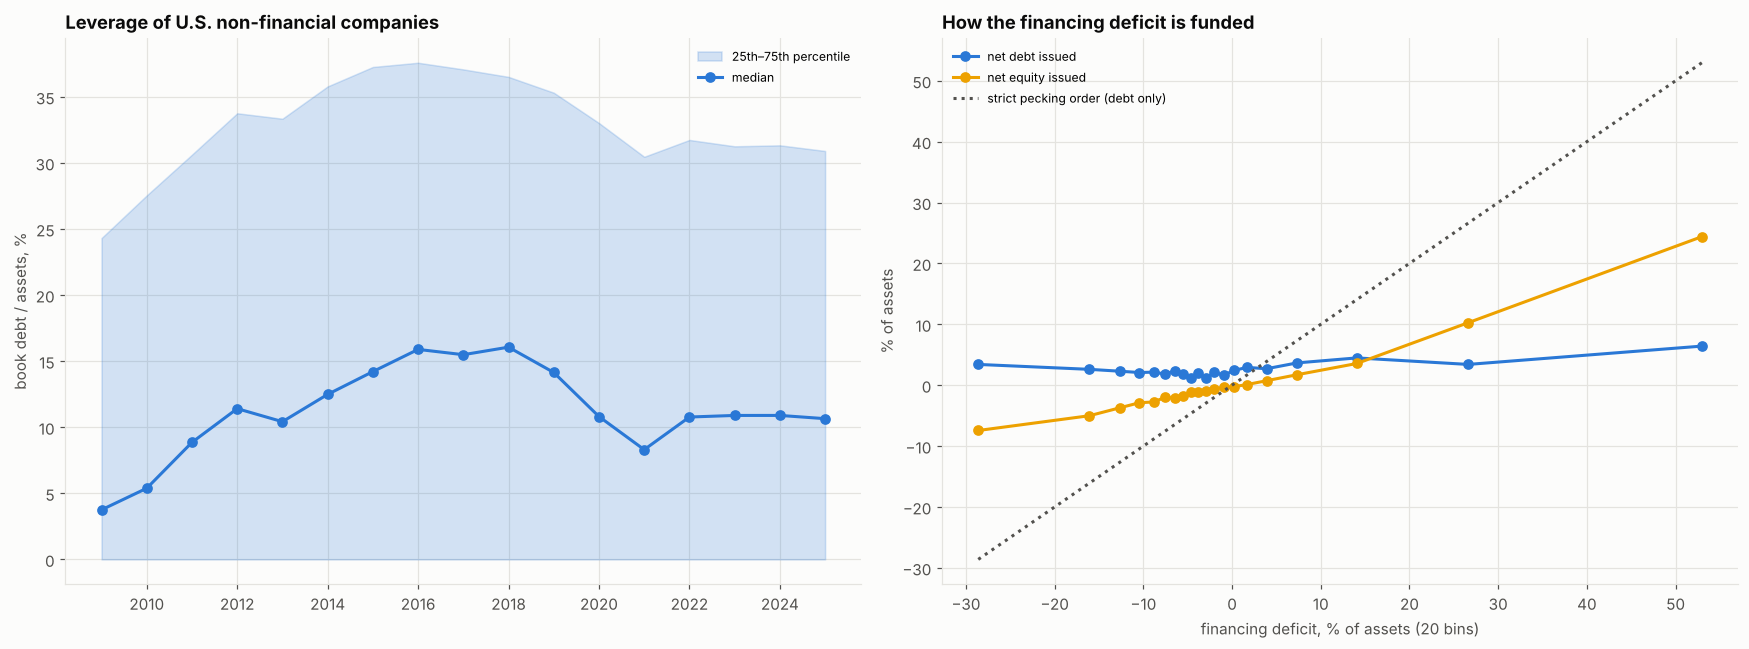

In [7]:
fig, ax = plt.subplots(1, 2, figsize=(16, 6))
a = ax[0]
med = A.groupby("cy").lev.median() * 100
q = A.groupby("cy").lev.quantile([0.25, 0.75]).unstack() * 100
a.fill_between(
    q.index,
    q[0.25],
    q[0.75],
    color=PALETTE[0],
    alpha=0.2,
    label="25th–75th percentile",
)
a.plot(med.index, med, "o-", color=PALETTE[0], label="median")
a.set_ylabel("book debt / assets, %")
a.set_title("Leverage of U.S. non-financial companies")
a.legend(fontsize=8)
a = ax[1]
Q["bin"] = pd.qcut(Q.deficit.rank(method="first"), 20, labels=False)
b = Q.groupby("bin")[["deficit", "net_debt", "net_equity"]].mean()
a.plot(
    b.deficit * 100,
    b.net_debt * 100,
    "o-",
    color=PALETTE[0],
    label="net debt issued",
)
a.plot(
    b.deficit * 100,
    b.net_equity * 100,
    "o-",
    color=PALETTE[3],
    label="net equity issued",
)
a.plot(
    [b.deficit.min() * 100, b.deficit.max() * 100],
    [b.deficit.min() * 100, b.deficit.max() * 100],
    color=INK_2,
    ls=":",
    label="strict pecking order (debt only)",
)
a.set_xlabel("financing deficit, % of assets (20 bins)")
a.set_ylabel("% of assets")
a.set_title("How the financing deficit is funded")
a.legend(fontsize=8)
fig.tight_layout()
save_fig(fig, "01_capital_structure")
plt.show()

In [8]:
BYY = O.groupby("year").apply(
    lambda d: pd.Series({
        m: (d[m] - d.actual).abs().mean() * 100
        for m in ["No change", "Partial adjustment", "LightGBM"]
    }),
    include_groups=False,
)
dash = make_subplots(
    rows=1,
    cols=2,
    subplot_titles=(
        "Pecking-order coefficient by sample",
        "Mean absolute error of next-year leverage (pp)",
    ),
)
dash.add_trace(
    go.Bar(
        x=PO.index,
        y=PO["net debt on deficit"],
        name="debt",
        marker_color=PALETTE[0],
    ),
    1,
    1,
)
dash.add_trace(
    go.Bar(
        x=PO.index,
        y=PO["net equity on deficit"],
        name="equity",
        marker_color=PALETTE[3],
    ),
    1,
    1,
)
for i, m in enumerate(BYY.columns):
    dash.add_trace(
        go.Scatter(x=BYY.index, y=BYY[m], name=m, line_color=PALETTE[i + 4]),
        1,
        2,
    )
dash.update_layout(
    height=550,
    width=1400,
    template="simple_white",
    barmode="group",
    title="Capital structure dynamics",
)
save_dashboard(dash, "dashboard")
dash.show()

Dashboard saved: outputs/dashboard.html and .png


## 6. Reading the results and limitations

**Leverage is persistent, and how persistent depends on the model.** For about 21,000 company-years of U.S. non-financial, non-utility companies, the partial-adjustment model estimated by pooled OLS closes only 11% of the gap to target each year (half-life almost six years). With firm fixed effects, which give each company its own target level, the speed is 46% (half-life about one year). The truth lies between: much of what looks like slow adjustment is permanent differences between companies (Lemmon, Roberts and Zender, 2008), but fixed effects are known to overstate the speed in short panels. The textbook claim that companies have targets and move towards them holds, at a speed of perhaps 20–40% a year.

**Targets follow the industry and size, not much else.** In the pooled model, target book leverage rises with the industry's median leverage (a coefficient of 0.38, t = 4.2), with size (+1.7 points per log unit of assets) and with sales growth. Profitability has the negative sign the pecking order predicts but is not significant once the industry is controlled for, and neither tangibility nor dividend payment matters much in book terms.

**The financing deficit is funded mainly with equity, not debt.** Regressing the change in debt on the financing deficit (dividends + capital expenditure − operating cash flow, scaled by assets) gives a coefficient of 0.06 across all companies and at most 0.12 for medium-sized companies, far from the 1.0 of a strict pecking order. Net equity issuance carries 0.37. Two things explain this: many deficits belong to small, loss-making companies (biotech, technology) that cannot borrow and issue shares, and large profitable companies run *surpluses* that they return through buybacks. As Frank and Goyal (2003) found, the pecking order describes large mature companies better than the cross-section, and even there only weakly.

**Next year's leverage is hard to beat as "same as this year".** The mean absolute error is 5.6 points for no change, 6.6 for the partial-adjustment model (which pulls companies towards a target they approach only slowly) and 5.8 for LightGBM. LightGBM and the partial-adjustment model explain only 3–5% of the *changes*: leverage moves with acquisitions, refinancings and losses that the characteristics cannot anticipate.

**The issuance choice is very predictable.** Among 3,949 company-years with a clear external issue, 82% raised debt. Trained on 2010–2018 and tested on 2019–2025, logistic regression separates debt from equity issuers with an AUC of 0.86 (LightGBM 0.85):

- **Debt issuers** are profitable, large, dividend-paying and capital-intensive (depreciation-heavy), which fits both the trade-off view (debt capacity) and the pecking order (good companies avoid equity).
- **Equity issuers** hold more cash and fewer tangible assets: early-stage companies without debt capacity.

**Limitations.**
- **Book, not market, leverage:** no market values are used; market leverage moves with stock prices and gives faster apparent adjustment.
- **Debt flows from balance-sheet changes:** acquisitions, currency effects and lease reclassifications (ASC 842 in 2019) change reported debt without issuance.
- **Equity issuance includes employee stock plans**, which inflates net equity issued for technology companies.
- **Dynamic-panel bias:** neither pooled OLS nor fixed effects is unbiased for λ; GMM or long-difference estimators would narrow the range.

In [9]:
SOA.to_csv(OUT_DIR / "speed_of_adjustment.csv")
TGT.to_csv(OUT_DIR / "target_leverage_determinants.csv")
PO.to_csv(OUT_DIR / "pecking_order_tests.csv")
LEVFC.to_csv(OUT_DIR / "leverage_forecasts.csv")
ISS.to_csv(OUT_DIR / "issuance_choice.csv")
print("Outputs written:", ", ".join(sorted(p.name for p in OUT_DIR.iterdir())))

Outputs written: 01_capital_structure.png, dashboard.html, dashboard.png, issuance_choice.csv, leverage_forecasts.csv, pecking_order_tests.csv, speed_of_adjustment.csv, target_leverage_determinants.csv


## References

- U.S. Securities and Exchange Commission. XBRL frames API and Financial Statement Data Sets. https://www.sec.gov/edgar/sec-api-documentation
- CFA Institute. *CFA Program Curriculum Level I*, Corporate Issuers: Capital Structure.
- Myers, S. C., & Majluf, N. S. (1984). Corporate financing and investment decisions when firms have information that investors do not have. *Journal of Financial Economics*, 13(2), 187–221.
- Shyam-Sunder, L., & Myers, S. C. (1999). Testing static tradeoff against pecking order models of capital structure. *Journal of Financial Economics*, 51(2), 219–244.
- Frank, M. Z., & Goyal, V. K. (2003). Testing the pecking order theory of capital structure. *Journal of Financial Economics*, 67(2), 217–248.
- Flannery, M. J., & Rangan, K. P. (2006). Partial adjustment toward target capital structures. *Journal of Financial Economics*, 79(3), 469–506.
- Lemmon, M. L., Roberts, M. R., & Zender, J. F. (2008). Back to the beginning: Persistence and the cross-section of corporate capital structure. *Journal of Finance*, 63(4), 1575–1608.